In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mudata

# from scenicplus.RSS import regulon_specificity_scores
# from scenicplus.eregulon_enrichment import binarize_AUC, get_eRegulons_as_signatures
# from scenicplus.plotting.correlation_plot import correlation_heatmap, jaccard_heatmap
# from scenicplus.plotting.coverageplot import coverage_plot
# from scenicplus.plotting.dotplot import heatmap_dotplot
# from scenicplus.scenicplus_class import mudata_to_scenicplus
# from scenicplus.utils import get_interaction_pr
# from scenicplus.enhancer_to_gene import *
# from scenicplus.grn_builder.modules import *

In [3]:
data_dir = "/data_vol/analysis_outputs/SCENIC/full_dataset/100_000_cells_scplus_pipeline_out"

In [4]:
scplus_mdata = mudata.read(f"{data_dir}/scplusmdata.h5mu")

# scplus_obj = mudata_to_scenicplus(
#     mdata = scplus_mdata,
#     path_to_cistarget_h5 = f"{data_dir}/ctx_results.hdf5",
#     path_to_dem_h5 = f"{data_dir}/dem_results.hdf5"
# )
# scplus_obj.uns["eRegulon_signatures"] = get_eRegulons_as_signatures(scplus_obj.uns["eRegulon_metadata"])

# rss = regulon_specificity_scores(scplus_mdata, 
#                                 variable = "scRNA_counts:L2_manual",
#                                 modalities = ["direct_gene_based_AUC", "extended_gene_based_AUC"])

/opt/conda/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/opt/conda/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/opt/conda/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/opt/conda/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/opt/conda/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/opt/conda/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/annda

In [5]:
group_by = scplus_mdata.obs["scRNA_counts:L3_manual"].tolist()
gene_auc_df = scplus_mdata["direct_gene_based_AUC"].to_df().groupby(group_by).mean()
region_auc_df = scplus_mdata["direct_region_based_AUC"].to_df().groupby(group_by).mean()
# check that the eRegulons are in the same order for gene and region-based AUCs
assert np.all([c.split("_(")[0] for c in gene_auc_df.columns] == [c.split("_(")[0] for c in region_auc_df.columns])

tf_names = [x.split("_")[0] for x in scplus_mdata["direct_gene_based_AUC"].var.index.values]
tf_expression = scplus_mdata["scRNA_counts"][:,tf_names].to_df()
tf_expression.columns = scplus_mdata["direct_gene_based_AUC"].var.index.values
tf_expression = tf_expression.groupby(group_by).mean()

max_gene_based_AUC = gene_auc_df.max(axis=0)
max_region_based_AUC = region_auc_df.max(axis=0)

selected_eRegulons_gene_based_names = max_gene_based_AUC[(max_gene_based_AUC > 0.25).values | (max_region_based_AUC > 0.25).values].index.values
selected_eRegulons_region_based_names = max_region_based_AUC[(max_gene_based_AUC > 0.25).values | (max_region_based_AUC > 0.25).values].index.values

def _scale(df):
    return (df - df.min())/(df.max() - df.min())

rescaled_gene_df = _scale(gene_auc_df[selected_eRegulons_gene_based_names])
rescaled_region_df = _scale(region_auc_df[selected_eRegulons_region_based_names])
rescaled_tf_expression_df = (tf_expression[selected_eRegulons_gene_based_names] - tf_expression[selected_eRegulons_gene_based_names].mean(axis=0))/tf_expression[selected_eRegulons_gene_based_names].std(axis=0)

/opt/conda/envs/scenicplus/lib/python3.11/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)
/opt/conda/envs/scenicplus/lib/python3.11/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)


(25, 24)
(25, 4)
(25, 39)
(25, 5)


/tmp/ipykernel_28747/2869999644.py:40: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


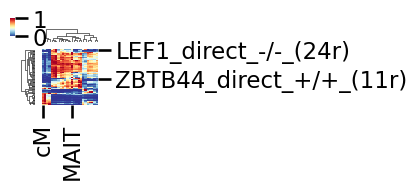

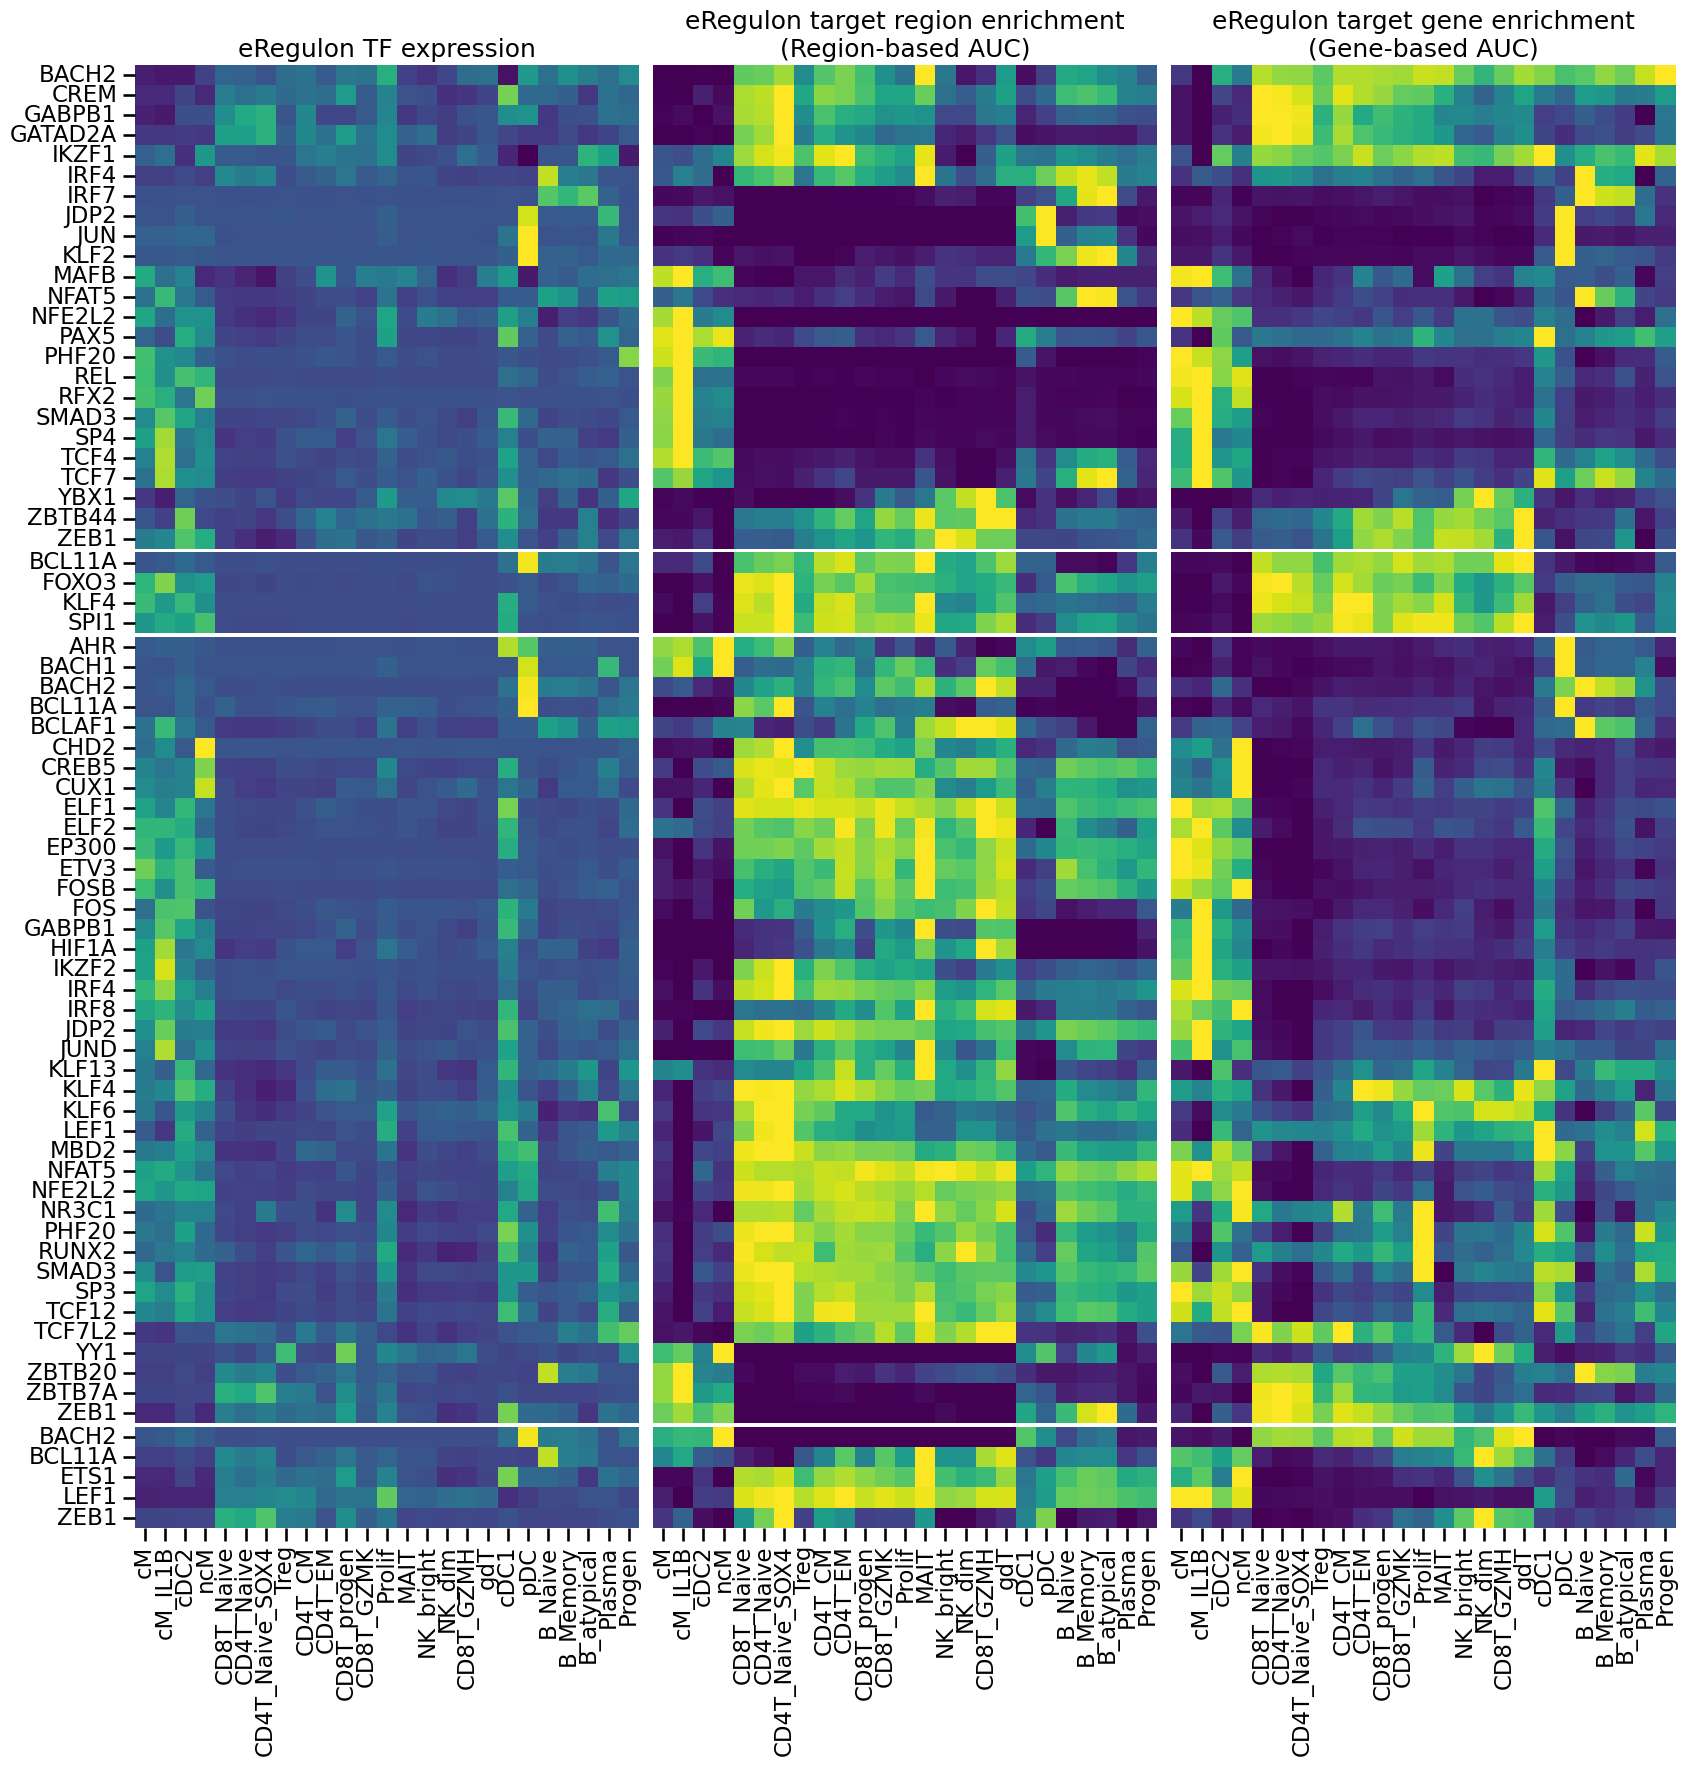

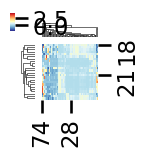

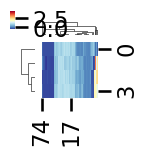

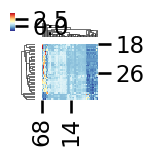

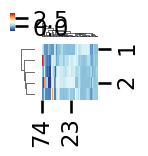

In [6]:
sns.set_context("talk", font_scale=1)
cg_region = sns.clustermap(rescaled_region_df.T, cmap="RdYlBu_r", figsize=(1,1))
split_activator_repressor = np.array([c.split("_")[2] for c in rescaled_gene_df.columns])

fig, ax = plt.subplots(4, 3, figsize=(20, 19), height_ratios=[6,1,9.75,1.25])
plt.subplots_adjust(hspace=0.01, wspace=0.01)
# plot triplet heatmap
for i, subset in enumerate(["+/+", "-/+", "+/-", "-/-"]):
    rescaled_gene_df_subset = rescaled_gene_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    print(rescaled_gene_df_subset.shape)
    rescaled_region_df_subset = rescaled_region_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    rescaled_tf_expression_df_subset = rescaled_tf_expression_df.iloc[:,np.where(split_activator_repressor == subset)[0]]

    cg_all = sns.clustermap(np.vstack([rescaled_gene_df_subset, rescaled_region_df_subset, rescaled_tf_expression_df_subset]).T, 
                            cmap="RdYlBu_r", figsize=(1,1))

    if i == 3:
        xticklabels = True
    else:
        xticklabels = False
    yticklabels = [c.split("_")[0] for c in rescaled_gene_df_subset.columns.values]

    sns.heatmap(rescaled_tf_expression_df_subset.T.iloc[cg_all.dendrogram_row.reordered_ind, cg_region.dendrogram_col.reordered_ind],
                yticklabels=yticklabels, xticklabels=xticklabels, ax=ax[i,0], vmin=-2, vmax=4.5,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_region_df_subset.T.iloc[cg_all.dendrogram_row.reordered_ind, cg_region.dendrogram_col.reordered_ind],
                yticklabels=False, xticklabels=xticklabels, ax=ax[i,1], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_gene_df_subset.T.iloc[cg_all.dendrogram_row.reordered_ind, cg_region.dendrogram_col.reordered_ind],
                yticklabels=False, xticklabels=xticklabels, ax=ax[i, 2], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    if i == 0:
        ax[i,0].set_title("eRegulon TF expression")
        ax[i,1].set_title("eRegulon target region enrichment\n(Region-based AUC)")
        ax[i,2].set_title("eRegulon target gene enrichment\n(Gene-based AUC)")

plt.tight_layout()
fig.savefig("/data/tmp_figures/eRegulon_triplet_heatmap_split_activator_repressor_vertical.pdf", dpi=300, bbox_inches="tight")
fig.savefig("/data/tmp_figures/eRegulon_triplet_heatmap_split_activator_repressor_vertical.png", dpi=300, bbox_inches="tight")

/opt/conda/envs/scenicplus/lib/python3.11/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)


(25, 24)


/opt/conda/envs/scenicplus/lib/python3.11/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)


(25, 4)
(25, 39)
(25, 5)


/tmp/ipykernel_28747/265128217.py:42: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


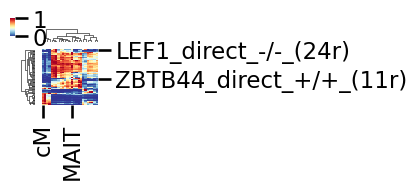

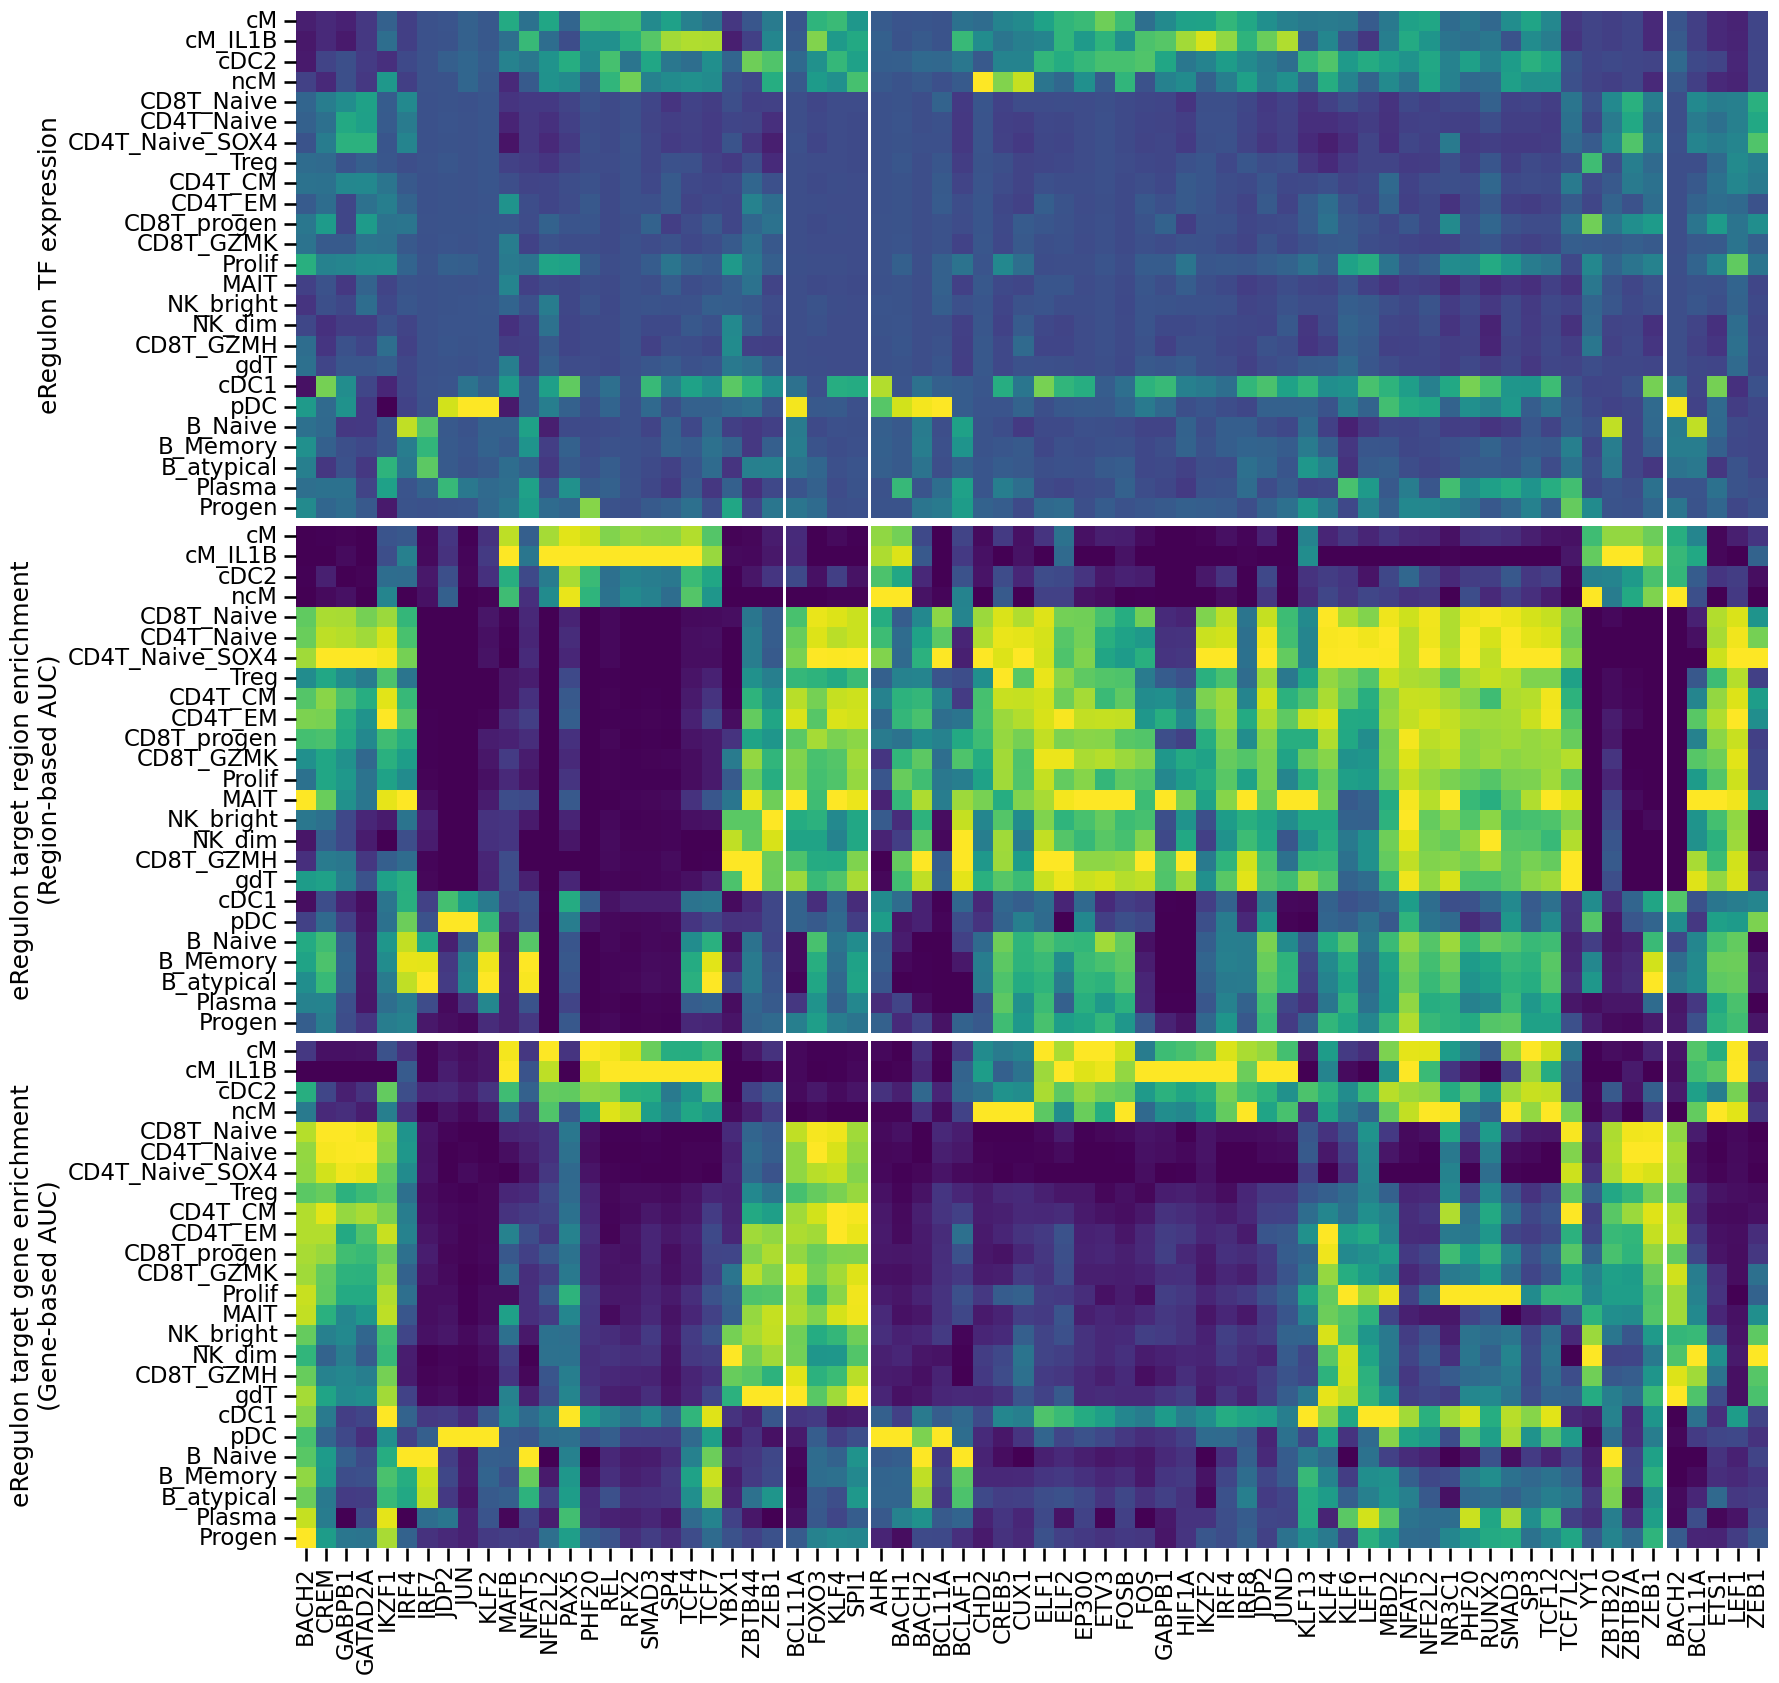

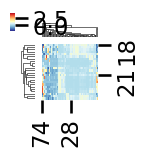

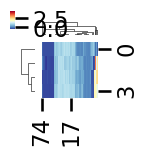

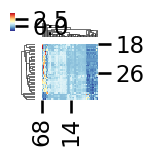

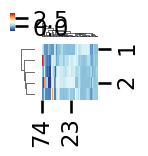

In [14]:
sns.set_context("talk", font_scale=1)
cg_region = sns.clustermap(rescaled_region_df.T, cmap="RdYlBu_r", figsize=(1,1))
split_activator_repressor = np.array([c.split("_")[2] for c in rescaled_gene_df.columns])

fig, ax = plt.subplots(3, 4, figsize=(19, 20), width_ratios=[6,1,9.75,1.25])
plt.subplots_adjust(hspace=0.01, wspace=0.01)
# plot triplet heatmap
for i, subset in enumerate(["+/+", "-/+", "+/-", "-/-"]):
    rescaled_gene_df_subset = rescaled_gene_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    print(rescaled_gene_df_subset.shape)
    rescaled_region_df_subset = rescaled_region_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    rescaled_tf_expression_df_subset = rescaled_tf_expression_df.iloc[:,np.where(split_activator_repressor == subset)[0]]

    cg_all = sns.clustermap(np.vstack([rescaled_gene_df_subset, rescaled_region_df_subset, rescaled_tf_expression_df_subset]).T, 
                            cmap="RdYlBu_r", figsize=(1,1))

    # fig, ax = plt.subplots(1, 3, figsize=(27, 18))

    if i == 0:
        yticklabels = True
    else:
        yticklabels = False
    xticklabels = [c.split("_")[0] for c in rescaled_gene_df_subset.columns.values]

    sns.heatmap(rescaled_tf_expression_df_subset.T.iloc[cg_all.dendrogram_row.reordered_ind, cg_region.dendrogram_col.reordered_ind].T,
                yticklabels=yticklabels, xticklabels=False, ax=ax[0,i], vmin=-2, vmax=4.5,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_region_df_subset.T.iloc[cg_all.dendrogram_row.reordered_ind, cg_region.dendrogram_col.reordered_ind].T,
                yticklabels=yticklabels, xticklabels=False, ax=ax[1,i], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_gene_df_subset.T.iloc[cg_all.dendrogram_row.reordered_ind, cg_region.dendrogram_col.reordered_ind].T,
                yticklabels=yticklabels, xticklabels=xticklabels, ax=ax[2,i], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    if i == 0:
        ax[0,i].set_ylabel("eRegulon TF expression")
        ax[1,i].set_ylabel("eRegulon target region enrichment\n(Region-based AUC)")
        ax[2,i].set_ylabel("eRegulon target gene enrichment\n(Gene-based AUC)")

plt.tight_layout()
fig.savefig("/data/tmp_figures/eRegulon_triplet_heatmap_split_activator_repressor_horizontal.pdf", dpi=300, bbox_inches="tight")
fig.savefig("/data/tmp_figures/eRegulon_triplet_heatmap_split_activator_repressor_horizontal.png", dpi=300, bbox_inches="tight")

In [ ]:
# default scenic dotplot viz
heatmap_dotplot(
    scplus_mudata = scplus_mdata,
    color_modality = "direct_gene_based_AUC",
    size_modality = "direct_region_based_AUC",
    group_variable = "scRNA_counts:L2_manual",
    eRegulon_metadata_key = "direct_e_regulon_metadata",
    color_feature_key = "Gene_signature_name",
    size_feature_key = "Region_signature_name",
    feature_name_key = "eRegulon_name",
    sort_data_by = "direct_gene_based_AUC",
    subset_feature_names = selected_eRegulons_gene_based_names,
    orientation = "horizontal",
    figsize = (18, 8),
    save="/data/tmp_figures/scenic_100_000_cells_dotplot_auc_0.25_threshold_horizontal.png"
)

heatmap_dotplot(
    scplus_mudata = scplus_mdata,
    color_modality = "direct_gene_based_AUC",
    size_modality = "direct_region_based_AUC",
    group_variable = "scRNA_counts:L2_manual",
    eRegulon_metadata_key = "direct_e_regulon_metadata",
    color_feature_key = "Gene_signature_name",
    size_feature_key = "Region_signature_name",
    feature_name_key = "eRegulon_name",
    sort_data_by = "direct_gene_based_AUC",
    subset_feature_names = selected_eRegulons_gene_based_names,
    orientation = "vertical",
    figsize = (8, 16),
    save="/data/tmp_figures/scenic_100_000_cells_dotplot_auc_0.25_threshold_vertical.png"
)

Plot sharing of target genes or target regions across eRegulons

In [ ]:
gene_based_jaccard_df, _ = jaccard_heatmap(scplus_obj,
                gene_or_region_based = "Gene_based",
                selected_regulons = selected_eRegulons_gene_based_names, 
                use_plotly=False, figsize=(22, 20),
                fontsize=9, vmax=0.4, return_data=True)
plt.tight_layout()

gene_based_jaccard_df.index = [i.split("_(")[0] for i in gene_based_jaccard_df.index]
gene_based_jaccard_df.columns = [i.split("_(")[0] for i in gene_based_jaccard_df.columns]
gene_based_order = gene_based_jaccard_df.index.values

In [ ]:
region_based_jaccard_df, _ = jaccard_heatmap(scplus_obj,
                gene_or_region_based = "Region_based",
                selected_regulons = selected_eRegulons_region_based_names, 
                use_plotly=False, figsize=(22, 20),
                fontsize=9, vmax=0.3, return_data=True)
plt.tight_layout()


region_based_jaccard_df.index = [i.split("_(")[0] for i in region_based_jaccard_df.index]
region_based_jaccard_df.columns = [i.split("_(")[0] for i in region_based_jaccard_df.columns]
region_based_order = region_based_jaccard_df.index.values

In [ ]:
# plot both target gene and target region sharing in one heatmap, ordered based on gene-based clustering
gene_based_jaccard_df = gene_based_jaccard_df.loc[gene_based_order, gene_based_order]
region_based_jaccard_df = region_based_jaccard_df.loc[gene_based_order, gene_based_order]
combined_mat = gene_based_jaccard_df.values
combined_mat[np.tril_indices(combined_mat.shape[0])] = region_based_jaccard_df.values[np.tril_indices(combined_mat.shape[0])]

# Create masks
mask_lower = np.triu(np.ones_like(combined_mat, dtype=bool)) # Mask for upper triangle (hides upper)
mask_upper = np.tril(np.ones_like(combined_mat, dtype=bool)) # Mask for lower triangle (hides lower)

# Create a figure and axes
fig, ax = plt.subplots(figsize=(22, 20))

# Plot the lower triangle with one palette
sns.heatmap(combined_mat, mask=mask_lower, square=True,
            cbar_kws={"shrink": .50, 'label': 'Region-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Blues', ax=ax, cbar=True,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

# Plot the upper triangle with a different palette
sns.heatmap(combined_mat, mask=mask_upper, square=True,
            cbar_kws={"shrink": .50, 'label': 'Target gene-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Reds', ax=ax,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

plt.savefig("/data/tmp_figures/scenic_100_000_cells_jaccard_heatmap.png", dpi=300, bbox_inches='tight')

In [ ]:
# plot both target gene and target region sharing in one heatmap, ordered based on region-based clustering
gene_based_jaccard_df = gene_based_jaccard_df.loc[region_based_order, region_based_order]
region_based_jaccard_df = region_based_jaccard_df.loc[region_based_order, region_based_order]
combined_mat = gene_based_jaccard_df.values
combined_mat[np.tril_indices(combined_mat.shape[0])] = region_based_jaccard_df.values[np.tril_indices(combined_mat.shape[0])]

# Create masks
mask_lower = np.triu(np.ones_like(combined_mat, dtype=bool)) # Mask for upper triangle (hides upper)
mask_upper = np.tril(np.ones_like(combined_mat, dtype=bool)) # Mask for lower triangle (hides lower)

# Create a figure and axes
fig, ax = plt.subplots(figsize=(22, 20))

# Plot the lower triangle with one palette
sns.heatmap(combined_mat, mask=mask_lower, square=True,
            cbar_kws={"shrink": .50, 'label': 'Region-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Blues', ax=ax, cbar=True,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

# Plot the upper triangle with a different palette
sns.heatmap(combined_mat, mask=mask_upper, square=True,
            cbar_kws={"shrink": .50, 'label': 'Target gene-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Reds', ax=ax,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

plt.show()